# Previsão de séries temporais: carga de energia elétrica do ONS

Neste notebook aplico as técnicas de *forecasting* da aula 09a ([`aula09a_forecasting.ipynb`](https://github.com/fboldt/aulasann/blob/main/aula09a_forecasting.ipynb)) a uma base diferente da usada em aula (Jena Climate). As técnicas são as mesmas: geração das janelas com `keras.utils.timeseries_dataset_from_array`, uma **técnica ingênua (*naive*) como baseline**, rede densa, rede convolucional 1D, LSTM, LSTM com *dropout* e LSTM bidirecional.

**Roteiro**

1. A base de dados
2. Análise exploratória
3. Pré-processamento
4. Geração do dataset a partir do array (e justificativa dos parâmetros)
5. Baseline ingênuo
6. Modelos de aprendizado profundo
7. Diagnóstico: mudança de nível entre treino e teste
8. Correção: normalização por janela
9. Comparação no conjunto de teste
10. Conclusões

In [1]:
import os
import re
import time
import urllib.request
import warnings
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

# o Keras avisa que ignora shuffle=True no fit quando recebe um tf.data.Dataset;
# o embaralhamento do treino já é feito pelo próprio timeseries_dataset_from_array
warnings.filterwarnings('ignore', message='`shuffle=True` was passed')

SEMENTE = 0
keras.utils.set_random_seed(SEMENTE)

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA, TINTA_SECUNDARIA = '#8a8984', '#52514e'
plt.rcParams.update({
    'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.5,
    'axes.edgecolor': TINTA_SECUNDARIA, 'axes.labelcolor': TINTA_SECUNDARIA,
    'xtick.color': TINTA_SECUNDARIA, 'ytick.color': TINTA_SECUNDARIA,
})
print(f'TensorFlow {tf.__version__} | Keras {keras.__version__} | GPUs: {tf.config.list_physical_devices("GPU")}')

TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: []


## 1. A base de dados

**Curva de carga horária do ONS.** O Operador Nacional do Sistema Elétrico publica no seu [portal de dados abertos](https://dados.ons.org.br/dataset/curva-carga) a carga de energia verificada **a cada hora**, em MW médios, em cada um dos quatro subsistemas do Sistema Interligado Nacional (SIN): Norte (N), Nordeste (NE), Sul (S) e Sudeste/Centro-Oeste (SE). Há um arquivo CSV por ano.

Uso os **10 anos completos de 2016 a 2025** (os anos de 2014 e 2015 têm dias inteiros faltando). A tarefa é prever a **carga do Sudeste/Centro-Oeste 24 horas à frente**, a partir da última semana de carga dos quatro subsistemas. O SE/CO é o maior subsistema do país, e a previsão para o dia seguinte é exatamente o horizonte que o ONS usa na programação diária da operação.

A estrutura é a mesma da base de Jena: uma matriz (tempo × variáveis) com várias séries medidas em intervalos regulares, da qual uma coluna é o alvo.

In [2]:
ANOS = range(2016, 2026)
URL = 'https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/curva-carga-ho/CURVA_CARGA_{ano}.csv'
PASTA_DADOS = Path('dados/ons')
PASTA_DADOS.mkdir(parents=True, exist_ok=True)

for ano in ANOS:
    destino = PASTA_DADOS / f'CURVA_CARGA_{ano}.csv'
    if not destino.exists():
        requisicao = urllib.request.Request(URL.format(ano=ano), headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(requisicao, timeout=120) as resposta:
            destino.write_bytes(resposta.read())
    print(f'{destino.name}: {destino.stat().st_size / 1e6:.1f} MB')

CURVA_CARGA_2016.csv: 1.5 MB
CURVA_CARGA_2017.csv: 1.5 MB
CURVA_CARGA_2018.csv: 1.5 MB
CURVA_CARGA_2019.csv: 1.5 MB
CURVA_CARGA_2020.csv: 1.5 MB
CURVA_CARGA_2021.csv: 1.5 MB
CURVA_CARGA_2022.csv: 1.5 MB
CURVA_CARGA_2023.csv: 1.5 MB
CURVA_CARGA_2024.csv: 1.5 MB
CURVA_CARGA_2025.csv: 1.4 MB


In [3]:
bruto = pd.concat([pd.read_csv(PASTA_DADOS / f'CURVA_CARGA_{ano}.csv', sep=';') for ano in ANOS])
bruto.head()

,id_subsistema,nom_subsistema,din_instante,val_cargaenergiahomwmed
0,N,NORTE,2016-01-01 00:00:00,4857.531000
1,NE,NORDESTE,2016-01-01 00:00:00,9130.105907
2,S,SUL,2016-01-01 00:00:00,8078.024000
3,SE,SUDESTE,2016-01-01 00:00:00,31924.942904
4,N,NORTE,2016-01-01 01:00:00,4724.366000


O arquivo está no formato "longo" (uma linha por subsistema e hora). Transformo em uma tabela com uma coluna por subsistema e uma linha por hora:

In [4]:
bruto['din_instante'] = pd.to_datetime(bruto['din_instante'])
SUBSISTEMAS = ['N', 'NE', 'S', 'SE']
carga = bruto.pivot_table(index='din_instante', columns='id_subsistema',
                          values='val_cargaenergiahomwmed')[SUBSISTEMAS]
carga.columns.name = None

horas = pd.date_range(f'{ANOS[0]}-01-01 00:00', f'{ANOS[-1]}-12-31 23:00', freq='h')
print(f'Horas esperadas: {len(horas)} | horas no arquivo: {len(carga)}')
print('Horas ausentes:', list(horas.difference(carga.index)))
print('Valores ausentes por coluna:', carga.isna().sum().to_dict())
print('Valores <= 0 por coluna:', (carga <= 0).sum().to_dict())

Horas esperadas: 87672 | horas no arquivo: 87670
Horas ausentes: [Timestamp('2016-10-16 00:00:00'), Timestamp('2017-10-15 00:00:00')]
Valores ausentes por coluna: {'N': 1, 'NE': 1, 'S': 0, 'SE': 1}
Valores <= 0 por coluna: {'N': 0, 'NE': 0, 'S': 1, 'SE': 0}


A base é muito limpa: faltam só as 2 horas "puladas" no início do horário de verão de 2016 e 2017, e em 2018-11-04 00:00 (também início do horário de verão) três subsistemas estão vazios e o Sul aparece com carga 0. Preencho esses 3 instantes por interpolação linear entre as horas vizinhas.

Quedas bruscas reais (como os apagões de 21/03/2018 e 15/08/2023 no Norte/Nordeste) são mantidas, pois fazem parte do fenômeno que se quer prever.

In [5]:
carga = carga.reindex(horas).mask(carga <= 0).interpolate()
assert not carga.isna().any().any()

n_amostras = len(carga)
print(f'Amostras: {n_amostras}')
print(f'Dias: {n_amostras / 24:.2f}')
print(f'Anos: {n_amostras / 24 / 365.25:.2f}')
print(f'Participação média do SE/CO na carga do SIN: {carga["SE"].sum() / carga.sum().sum():.1%}')
carga.describe().round(0)

Amostras: 87672
Dias: 3653.00
Anos: 10.00
Participação média do SE/CO na carga do SIN: 57.1%


,N,NE,S,SE
count,87672.0,87672.0,87672.0,87672.0
mean,6254.0,11243.0,11903.0,39105.0
std,1186.0,1616.0,2519.0,6557.0
min,842.0,665.0,5756.0,21491.0
25%,5389.0,10113.0,9960.0,34294.0
50%,5888.0,11134.0,11960.0,39067.0
75%,7069.0,12263.0,13587.0,43637.0
max,10239.0,18157.0,22737.0,62150.0


## 2. Análise exploratória

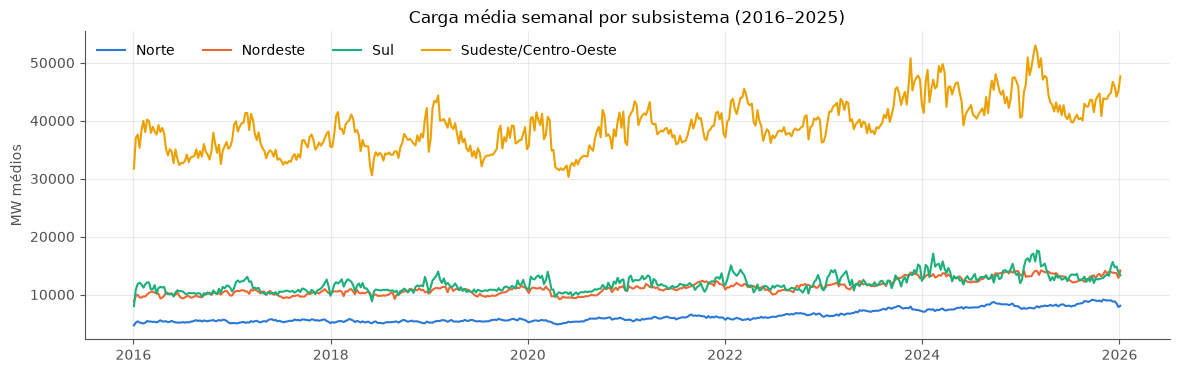

In [6]:
CORES = dict(zip(SUBSISTEMAS, [AZUL, LARANJA, VERDE, AMARELO]))
NOMES = {'N': 'Norte', 'NE': 'Nordeste', 'S': 'Sul', 'SE': 'Sudeste/Centro-Oeste'}

fig, ax = plt.subplots(figsize=(14, 4))
semanal = carga.resample('W').mean()
for sub in SUBSISTEMAS:
    ax.plot(semanal.index, semanal[sub], color=CORES[sub], label=NOMES[sub])
ax.set(title='Carga média semanal por subsistema (2016–2025)', ylabel='MW médios')
ax.legend(ncol=4, loc='upper left', frameon=False)
plt.show()

O SE/CO tem a maior carga e a maior variação: tendência de crescimento, sazonalidade anual (mais carga no verão, por causa do ar-condicionado) e a queda de 2020 por causa da pandemia de COVID-19. Ampliando para três semanas aparecem os dois ciclos mais importantes para a previsão de curto prazo:

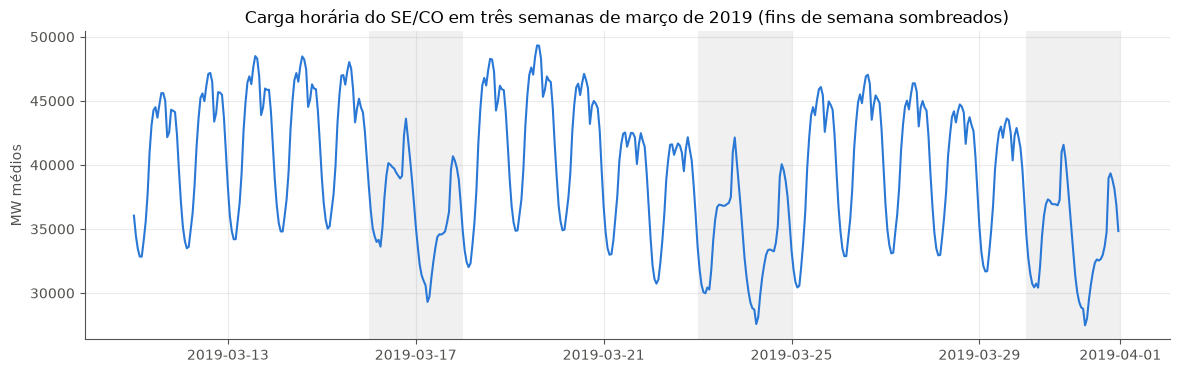

In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
trecho = carga.loc['2019-03-11':'2019-03-31', 'SE']
ax.plot(trecho.index, trecho, color=AZUL)
for dia in pd.date_range('2019-03-11', '2019-03-31', freq='D'):
    if dia.dayofweek >= 5:
        ax.axvspan(dia, dia + pd.Timedelta(days=1), color=CINZA, alpha=0.12, lw=0)
ax.set(title='Carga horária do SE/CO em três semanas de março de 2019 (fins de semana sombreados)', ylabel='MW médios')
plt.show()

- **Ciclo diário**: a carga cai de madrugada e tem pico à tarde/início da noite.
- **Ciclo semanal**: sábados e, principalmente, domingos têm carga bem menor que os dias úteis.

A autocorrelação da série (calculada só no período de treino) confirma isso: os picos estão em múltiplos de 24 horas, e o maior deles, depois do lag 0, está em **168 horas = 1 semana**. Essa informação é usada para escolher os parâmetros do dataset na seção 4.

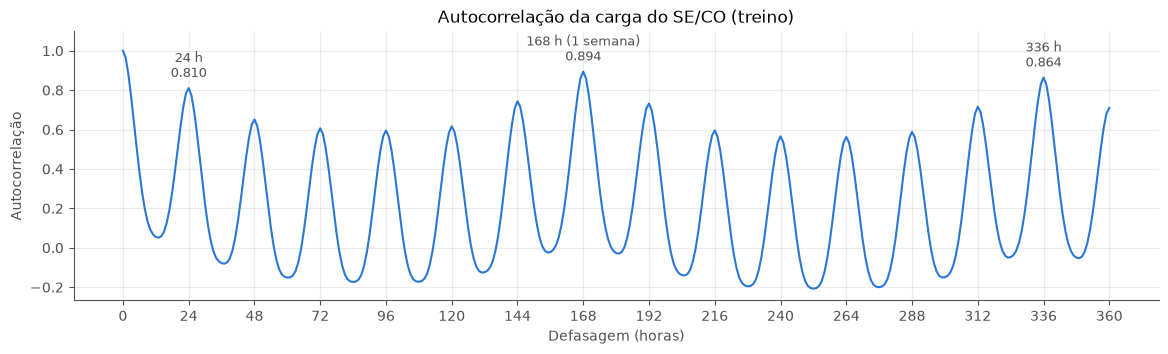

In [8]:
lags = np.arange(0, 24 * 15 + 1)
serie_treino = carga.loc[:'2021', 'SE']
autocorrelacao = np.array([serie_treino.autocorr(lag) for lag in lags])

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(lags, autocorrelacao, color=AZUL)
for lag, rotulo in [(24, '24 h'), (168, '168 h (1 semana)'), (336, '336 h')]:
    ax.annotate(f'{rotulo}\n{autocorrelacao[lag]:.3f}', (lag, autocorrelacao[lag]),
                xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9, color=TINTA_SECUNDARIA)
ax.set(title='Autocorrelação da carga do SE/CO (treino)', xlabel='Defasagem (horas)', ylabel='Autocorrelação',
       xticks=range(0, lags[-1] + 1, 24), ylim=(None, 1.1))
plt.show()

## 3. Pré-processamento

**Variáveis de entrada.** Além das cargas dos quatro subsistemas, acrescento quatro variáveis de calendário: seno e cosseno da hora do dia e do dia da semana. A codificação seno/cosseno é cíclica (23h fica perto de 0h, domingo fica perto de segunda) e informa à rede *quando* cada medição foi feita. Isso é importante porque o alvo cai 24 horas depois da última medição, e a rede precisa saber se esse dia seguinte é dia útil ou fim de semana. Ficam 8 variáveis por hora.

**Divisão temporal** (sem embaralhar, para não usar o futuro para prever o passado), por anos inteiros para que cada conjunto tenha todas as estações:

| Conjunto | Período | Proporção |
|---|---|---|
| Treino | 2016–2021 (inclui a pandemia) | 60% |
| Validação | 2022–2023 | 20% |
| Teste | 2024–2025 | 20% |

**Normalização.** Como na aula, subtraio a média e divido pelo desvio padrão de cada coluna, calculados **apenas no treino**. Uma diferença em relação à aula: lá o alvo (temperatura, na casa de 10 °C) entrava na escala original; aqui a carga do SE/CO está na casa de 40.000 MW, e treinar uma saída linear com MSE nessa escala atrapalha a otimização. Por isso o alvo também é a coluna **normalizada**, e as previsões são convertidas de volta para MW na hora de calcular os erros.

In [9]:
hora = carga.index.hour.to_numpy()
dia_semana = carga.index.dayofweek.to_numpy()
calendario = np.stack([np.sin(2 * np.pi * hora / 24), np.cos(2 * np.pi * hora / 24),
                       np.sin(2 * np.pi * dia_semana / 7), np.cos(2 * np.pi * dia_semana / 7)], axis=1)

COLUNAS = SUBSISTEMAS + ['sen_hora', 'cos_hora', 'sen_dia', 'cos_dia']
raw_data = np.concatenate([carga.to_numpy(), calendario], axis=1).astype('float32')
ALVO = COLUNAS.index('SE')
num_features = raw_data.shape[1]

num_train_samples = int((carga.index.year <= 2021).sum())
num_val_samples = int(carga.index.year.isin([2022, 2023]).sum())
num_test_samples = n_amostras - num_train_samples - num_val_samples
print(f'raw_data: {raw_data.shape}  (colunas: {COLUNAS})')
print(f'Train: {num_train_samples}')
print(f'Val: {num_val_samples}')
print(f'Test: {num_test_samples}')

mean = raw_data[:num_train_samples].mean(axis=0)
std = raw_data[:num_train_samples].std(axis=0)
dados = (raw_data - mean) / std
print(f'\nAlvo (SE/CO): média = {mean[ALVO]:.1f} MW | desvio padrão = {std[ALVO]:.1f} MW')

raw_data: (87672, 8)  (colunas: ['N', 'NE', 'S', 'SE', 'sen_hora', 'cos_hora', 'sen_dia', 'cos_dia'])
Train: 52608
Val: 17520
Test: 17544

Alvo (SE/CO): média = 36801.7 MW | desvio padrão = 5680.6 MW


## 4. Geração do dataset a partir do array

Como na aula, `keras.utils.timeseries_dataset_from_array` recebe o array completo e gera, sob demanda, as janelas de entrada e os alvos correspondentes. Cada amostra é uma janela de `sequence_length` instantes, pegando um a cada `sampling_rate` linhas; o alvo da janela que começa na linha `i` é `targets[i]`. Passando `data = dados[:-delay]` e `targets = dados[delay:, ALVO]`, o alvo da janela que começa em `i` é a carga do SE/CO na linha `i + delay`.

| Parâmetro | Aula (Jena) | Aqui (ONS) | Justificativa |
|---|---|---|---|
| `sampling_rate` | 6 | **1** | Jena tem uma medida a cada 10 min e a aula pegava 1 a cada 6 para ter dados horários. A base do ONS **já é horária**; subamostrar mais (de 2 em 2 h, por exemplo) apagaria a forma da curva diária (rampa da manhã, pico do fim da tarde). |
| `sequence_length` | 120 (5 dias) | **168 (7 dias)** | O ciclo mais longo relevante para o dia seguinte é o **semanal**: a autocorrelação tem pico em 168 h. Com uma semana inteira na janela, a rede vê o mesmo dia da semana que vai prever e o último fim de semana. Janelas maiores aumentariam o custo das redes recorrentes sem trazer um ciclo novo. |
| `delay` | 6 × (120 + 24 − 1) | **1 × (168 + 24 − 1) = 191** | Mesma fórmula da aula: a última linha da janela é `i + sampling_rate × (sequence_length − 1)`, e somar mais `sampling_rate × 24` coloca o alvo **24 horas depois da última medição**, que é o horizonte de previsão do dia seguinte. |
| `targets` | temperatura | **coluna SE/CO normalizada** | Variável que queremos prever (ver normalização na seção 3). |
| `batch_size` | 256 | **256** | Mesmo valor da aula; dá ~200 lotes por época no treino, rápido o bastante na CPU. |
| `shuffle` | `True` | **`True` no treino, `False` na validação/teste** | Embaralhar as janelas do treino evita lotes formados só por horas consecutivas, o que deixaria os gradientes correlacionados. Cada janela continua íntegra; o embaralhamento é *entre* janelas. Na validação/teste a ordem não muda o erro e mantê-la permite desenhar as previsões no tempo. |
| `start_index` / `end_index` | 50% / 25% / 25% | **anos inteiros** | Delimitam onde as janelas podem estar no array. Para que nenhum **alvo** do treino caia dentro da validação (e nenhum da validação dentro do teste), o `end_index` é recuado em 24 horas. |

In [10]:
sampling_rate = 1
sequence_length = 24 * 7
horizonte = 24
delay = sampling_rate * (sequence_length + horizonte - 1)
batch_size = 256
print(f'delay = {delay}')


def criar_dataset(start_index, end_index, shuffle):
    return keras.utils.timeseries_dataset_from_array(
        dados[:-delay],
        targets=dados[delay:, ALVO],
        sampling_rate=sampling_rate,
        sequence_length=sequence_length,
        shuffle=shuffle,
        batch_size=batch_size,
        start_index=start_index,
        end_index=end_index,
        seed=SEMENTE,
    )


fim_treino = num_train_samples
fim_val = num_train_samples + num_val_samples
train_dataset = criar_dataset(0, fim_treino - horizonte, shuffle=True)
val_dataset = criar_dataset(fim_treino, fim_val - horizonte, shuffle=False)
test_dataset = criar_dataset(fim_val, None, shuffle=False)

for samples, targets in train_dataset:
    print('samples shape:', samples.shape)
    print('targets shape:', targets.shape)
    break

delay = 191


samples shape: (256, 168, 8)
targets shape: (256,)


Conferência do alinhamento com datas reais: para a primeira janela de cada conjunto, mostro o intervalo coberto pela entrada e o instante do alvo, e confiro se o valor do alvo devolvido pelo Keras é a carga do SE/CO naquele instante.

In [11]:
def instantes_janela(inicio):
    ultima = inicio + sampling_rate * (sequence_length - 1)
    return carga.index[inicio], carga.index[ultima], carga.index[inicio + delay]


for nome, dataset, inicio in [('treino', criar_dataset(0, fim_treino - horizonte, shuffle=False), 0),
                               ('validação', val_dataset, fim_treino), ('teste', test_dataset, fim_val)]:
    amostras, alvos = next(iter(dataset))
    de, ate, alvo = instantes_janela(inicio)
    alvo_keras_mw = alvos[0].numpy() * std[ALVO] + mean[ALVO]
    assert np.isclose(alvo_keras_mw, carga.loc[alvo, 'SE'], rtol=1e-4)
    print(f'{nome:>9}: entrada {de:%d/%m/%Y %H:%M} → {ate:%d/%m/%Y %H:%M} | alvo {alvo:%d/%m/%Y %H:%M} '
          f'= {alvo_keras_mw:,.0f} MW')

n_janelas = {nome: sum(int(a.shape[0]) for a, _ in ds)
             for nome, ds in [('treino', train_dataset), ('validação', val_dataset), ('teste', test_dataset)]}
print('\nJanelas por conjunto:', n_janelas)
print(f'Último alvo do treino:    {carga.index[fim_treino - horizonte - sequence_length + delay]}')
print(f'Último alvo da validação: {carga.index[fim_val - horizonte - sequence_length + delay]}')

   treino: entrada 01/01/2016 00:00 → 07/01/2016 23:00 | alvo 08/01/2016 23:00 = 39,392 MW
validação: entrada 01/01/2022 00:00 → 07/01/2022 23:00 | alvo 08/01/2022 23:00 = 36,966 MW
    teste: entrada 01/01/2024 00:00 → 07/01/2024 23:00 | alvo 08/01/2024 23:00 = 47,459 MW



Janelas por conjunto: {'treino': 52417, 'validação': 17329, 'teste': 17186}
Último alvo do treino:    2021-12-31 23:00:00
Último alvo da validação: 2023-12-31 23:00:00


## 5. Baseline ingênuo

Como pede a tarefa, antes de qualquer rede defino o que é um bom resultado com métodos sem aprendizado. Uso dois *naive*:

- **Ingênuo (último valor)**: o mesmo da aula, `samples[:, -1, ALVO]`, ou seja, a previsão é o último valor observado. Como o alvo está 24 h depois da última medição, isso equivale a dizer que **a carga amanhã nesta hora será igual à de hoje nesta hora**.
- **Ingênuo sazonal semanal**: a previsão é a carga **no mesmo dia da semana e hora, uma semana antes do alvo**. O alvo está em `t + 24`; uma semana antes é `t − 144`, que é a posição 23 da janela de 168 horas (`samples[:, 23, ALVO]`). Ele acerta melhor as transições entre dia útil e fim de semana, que o "último valor" erra sistematicamente (prevê domingo como sábado e segunda como domingo).

Além do MAE (em MW médios, como na aula), mostro o MAPE (erro percentual absoluto médio), que é mais fácil de interpretar para cargas.

In [12]:
def para_mw(valores_normalizados):
    return np.asarray(valores_normalizados) * std[ALVO] + mean[ALVO]


def prever(dataset, previsor):
    previsto, real = [], []
    for samples, targets in dataset:
        previsto.append(np.asarray(previsor(samples)).reshape(-1))
        real.append(targets.numpy())
    return para_mw(np.concatenate(previsto)), para_mw(np.concatenate(real))


def metricas(previsto, real):
    return {'MAE (MW)': np.mean(np.abs(previsto - real)),
            'MAPE (%)': 100 * np.mean(np.abs(previsto - real) / real),
            'Viés (MW)': np.mean(previsto - real)}


resultados = {}
previsoes = {}  # (método, conjunto) -> previsões em MW
reais = {}  # conjunto -> valores reais em MW


def registrar(nome, previsor):
    linha = {}
    for conjunto, dataset in [('val', val_dataset), ('teste', test_dataset)]:
        previsto, real = prever(dataset, previsor)
        previsoes[nome, conjunto], reais[conjunto] = previsto, real
        for metrica, valor in metricas(previsto, real).items():
            linha[f'{metrica} {conjunto}'] = valor
    resultados[nome] = linha
    print(f'{nome}: Validation MAE: {linha["MAE (MW) val"]:.0f} MW ({linha["MAPE (%) val"]:.2f}%) | '
          f'Test MAE: {linha["MAE (MW) teste"]:.0f} MW ({linha["MAPE (%) teste"]:.2f}%)')


registrar('Ingênuo (último valor)', lambda samples: samples[:, -1, ALVO])
registrar('Ingênuo sazonal (semana anterior)', lambda samples: samples[:, sequence_length - 1 - (168 - horizonte), ALVO])

Ingênuo (último valor): Validation MAE: 2431 MW (6.11%) | Test MAE: 2585 MW (5.92%)


Ingênuo sazonal (semana anterior): Validation MAE: 2013 MW (4.96%) | Test MAE: 2312 MW (5.24%)


O ingênuo sazonal semanal é o baseline a ser batido: erra em média cerca de 2.000 MW na validação e 2.300 MW no teste (≈ 5%). Uma rede que não fique abaixo disso não aprendeu nada além de "copiar a semana passada".

## 6. Modelos de aprendizado profundo

Treino as mesmas arquiteturas da aula. Para a comparação ser justa, todas usam a mesma configuração de treino:

- perda MSE e métrica MAE (como na aula), otimizador **Adam** (na aula, as redes densa e convolucional usaram RMSprop e as recorrentes Adam; aqui uso Adam em todas para que a diferença venha só da arquitetura);
- até 30 épocas, guardando o modelo com menor perda de validação (`ModelCheckpoint(save_best_only=True)`, como na aula) e interrompendo se a validação não melhorar por 6 épocas seguidas (`EarlyStopping`);
- mesma semente aleatória.

As curvas de MAE estão em MW, com os dois baselines desenhados como referência.

In [13]:
EPOCAS = 30
PASTA_MODELOS = Path('dados/ons/modelos')
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)


def treinar(nome, construir):
    keras.utils.set_random_seed(SEMENTE)
    inputs = keras.Input(shape=(sequence_length, num_features))
    model = keras.Model(inputs, construir(inputs), name=re.sub(r'\W+', '_', nome).strip('_'))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    print(f'{model.name}: {model.count_params():,} parâmetros')

    arquivo = PASTA_MODELOS / f'{model.name}.keras'
    callbacks = [keras.callbacks.ModelCheckpoint(arquivo, save_best_only=True),
                 keras.callbacks.EarlyStopping(patience=6)]
    inicio = time.time()
    history = model.fit(train_dataset, epochs=EPOCAS, validation_data=val_dataset, callbacks=callbacks, verbose=2)
    print(f'Tempo de treino: {time.time() - inicio:.0f} s')

    model = keras.models.load_model(arquivo)
    registrar(nome, lambda samples: model(samples, training=False))
    plotar_historico(nome, history)
    return model


def plotar_historico(nome, history):
    train_mae = np.array(history.history['mae']) * std[ALVO]
    val_mae = np.array(history.history['val_mae']) * std[ALVO]
    epochs = range(1, len(train_mae) + 1)
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(epochs, train_mae, 'o-', color=AZUL, ms=4, label='treino')
    ax.plot(epochs, val_mae, 'o-', color=LARANJA, ms=4, label='validação')
    for baseline, estilo in [('Ingênuo (último valor)', ':'), ('Ingênuo sazonal (semana anterior)', '--')]:
        ax.axhline(resultados[baseline]['MAE (MW) val'], color=CINZA, ls=estilo, lw=1.2,
                   label=f'{baseline} (validação)')
    melhor = int(np.argmin(history.history['val_loss']))
    ax.plot(melhor + 1, val_mae[melhor], 'o', ms=10, mfc='none', mec=LARANJA, mew=1.5)
    ax.set(title=f'{nome}: MAE por época', xlabel='Época', ylabel='MAE (MW)', ylim=(0, None))
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

### 6.1 Rede densa

Igual à da aula: a janela inteira (168 × 8) é achatada em um vetor e passa por uma camada densa de 16 neurônios. A rede não sabe que os valores estão em ordem temporal, mas pode aprender pesos específicos para cada posição da janela (por exemplo, "mesma hora de ontem" e "mesma hora da semana passada").

Densa: 21,537 parâmetros
Epoch 1/30


205/205 - 4s - 22ms/step - loss: 0.1934 - mae: 0.3030 - val_loss: 0.2658 - val_mae: 0.3845


Epoch 2/30


205/205 - 4s - 18ms/step - loss: 0.0939 - mae: 0.2207 - val_loss: 0.1490 - val_mae: 0.2773


Epoch 3/30


...

205/205 - 3s - 15ms/step - loss: 0.0528 - mae: 0.1583 - val_loss: 0.1035 - val_mae: 0.2326


Epoch 19/30


205/205 - 3s - 15ms/step - loss: 0.0529 - mae: 0.1588 - val_loss: 0.1401 - val_mae: 0.2754


Tempo de treino: 66 s


Densa: Validation MAE: 1301 MW (3.19%) | Test MAE: 2232 MW (5.14%)


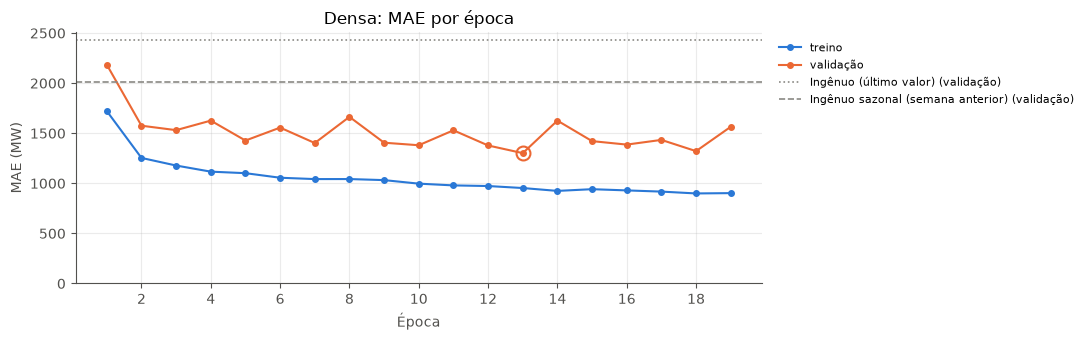

In [14]:
def densa(inputs):
    x = layers.Flatten()(inputs)
    x = layers.Dense(16, activation='relu')(x)
    return layers.Dense(1)(x)


modelo_densa = treinar('Densa', densa)

### 6.2 Rede convolucional 1D

Mesma arquitetura da aula. Aqui o primeiro filtro de tamanho **24** tem uma interpretação direta: ele cobre exatamente **um dia** de dados horários. Depois de dois *max pooling*, os filtros de 12 e 6 posições ainda enxergam blocos de cerca de 2 e 4 dias.

Conv1D: 2,721 parâmetros
Epoch 1/30


205/205 - 5s - 26ms/step - loss: 0.5548 - mae: 0.6144 - val_loss: 0.3715 - val_mae: 0.4680


Epoch 2/30


205/205 - 5s - 24ms/step - loss: 0.2099 - mae: 0.3540 - val_loss: 0.2664 - val_mae: 0.3848


Epoch 3/30


...

205/205 - 4s - 20ms/step - loss: 0.1341 - mae: 0.2726 - val_loss: 0.2323 - val_mae: 0.3585


Epoch 11/30


205/205 - 4s - 21ms/step - loss: 0.1327 - mae: 0.2711 - val_loss: 0.2437 - val_mae: 0.3731


Tempo de treino: 48 s


Conv1D: Validation MAE: 2026 MW (5.04%) | Test MAE: 2521 MW (5.67%)


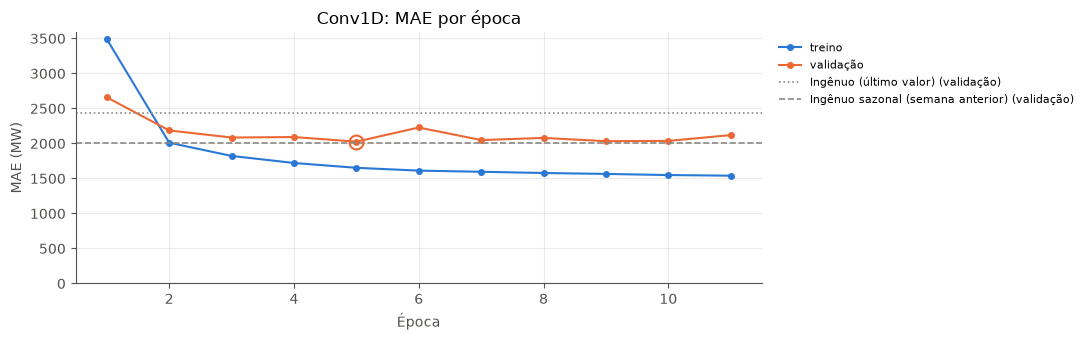

In [15]:
def convolucional(inputs):
    x = layers.Conv1D(8, 24, activation='relu')(inputs)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(8, 12, activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(8, 6, activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)
    return layers.Dense(1)(x)


modelo_conv = treinar('Conv1D', convolucional)

### 6.3 LSTM

Uma camada LSTM com 16 unidades lê a janela hora a hora e resume a semana em seu estado interno; uma camada densa produz a previsão.

LSTM: 1,617 parâmetros
Epoch 1/30


205/205 - 17s - 82ms/step - loss: 0.5313 - mae: 0.5496 - val_loss: 0.4860 - val_mae: 0.5057


Epoch 2/30


205/205 - 13s - 65ms/step - loss: 0.1161 - mae: 0.2499 - val_loss: 0.2293 - val_mae: 0.3304


Epoch 3/30


...

205/205 - 15s - 74ms/step - loss: 0.0453 - mae: 0.1441 - val_loss: 0.1054 - val_mae: 0.2268


Epoch 29/30


205/205 - 16s - 78ms/step - loss: 0.0449 - mae: 0.1435 - val_loss: 0.1110 - val_mae: 0.2323


Tempo de treino: 403 s


LSTM: Validation MAE: 1276 MW (3.09%) | Test MAE: 2154 MW (4.82%)


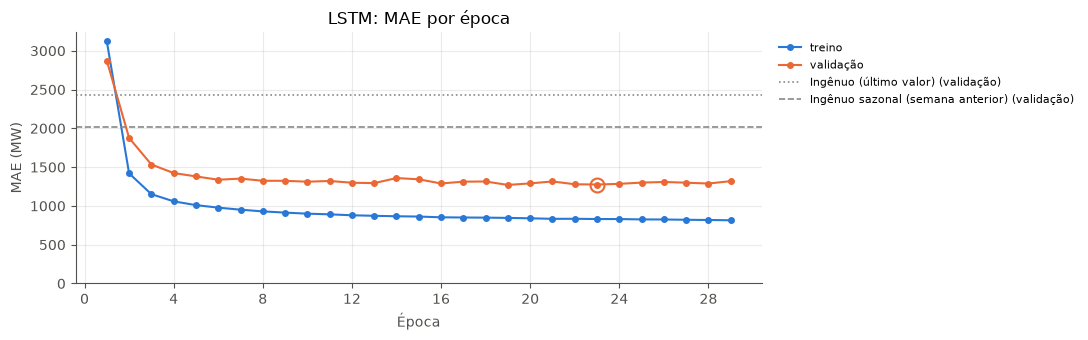

In [16]:
def lstm(inputs):
    x = layers.LSTM(16)(inputs)
    return layers.Dense(1)(x)


modelo_lstm = treinar('LSTM', lstm)

### 6.4 LSTM com dropout

Como na aula, acrescento `Dropout(0.5)` entre a LSTM e a camada de saída para reduzir o sobreajuste.

LSTM_com_dropout: 1,617 parâmetros
Epoch 1/30


205/205 - 15s - 72ms/step - loss: 0.5143 - mae: 0.5577 - val_loss: 0.5015 - val_mae: 0.5275


Epoch 2/30


205/205 - 14s - 67ms/step - loss: 0.2406 - mae: 0.3788 - val_loss: 0.3596 - val_mae: 0.4328


Epoch 3/30


...

205/205 - 13s - 65ms/step - loss: 0.1266 - mae: 0.2598 - val_loss: 0.1500 - val_mae: 0.2818


Epoch 30/30


205/205 - 14s - 66ms/step - loss: 0.1265 - mae: 0.2601 - val_loss: 0.1245 - val_mae: 0.2537


Tempo de treino: 407 s


LSTM com dropout: Validation MAE: 1362 MW (3.33%) | Test MAE: 2112 MW (4.67%)


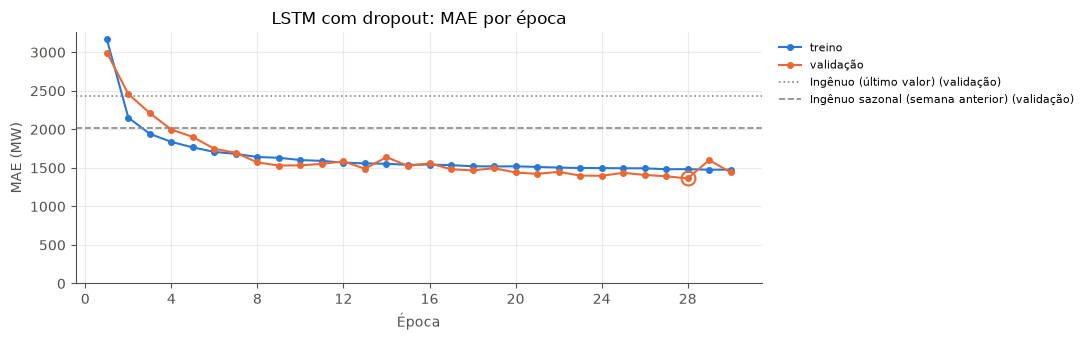

In [17]:
def lstm_dropout(inputs):
    x = layers.LSTM(16)(inputs)
    x = layers.Dropout(0.5)(x)
    return layers.Dense(1)(x)


modelo_lstm_dropout = treinar('LSTM com dropout', lstm_dropout)

### 6.5 LSTM bidirecional

A camada `Bidirectional` processa a janela nos dois sentidos (do passado para o presente e do presente para o passado) e concatena os dois estados finais.

LSTM_bidirecional: 3,233 parâmetros
Epoch 1/30


205/205 - 19s - 95ms/step - loss: 0.4047 - mae: 0.4919 - val_loss: 0.4437 - val_mae: 0.4931


Epoch 2/30


205/205 - 19s - 92ms/step - loss: 0.1914 - mae: 0.3357 - val_loss: 0.3062 - val_mae: 0.4049


Epoch 3/30


...

205/205 - 17s - 83ms/step - loss: 0.1060 - mae: 0.2399 - val_loss: 0.1712 - val_mae: 0.2741


Epoch 13/30


205/205 - 17s - 84ms/step - loss: 0.1045 - mae: 0.2372 - val_loss: 0.1695 - val_mae: 0.2741


Tempo de treino: 227 s


LSTM bidirecional: Validation MAE: 1570 MW (3.72%) | Test MAE: 3080 MW (6.56%)


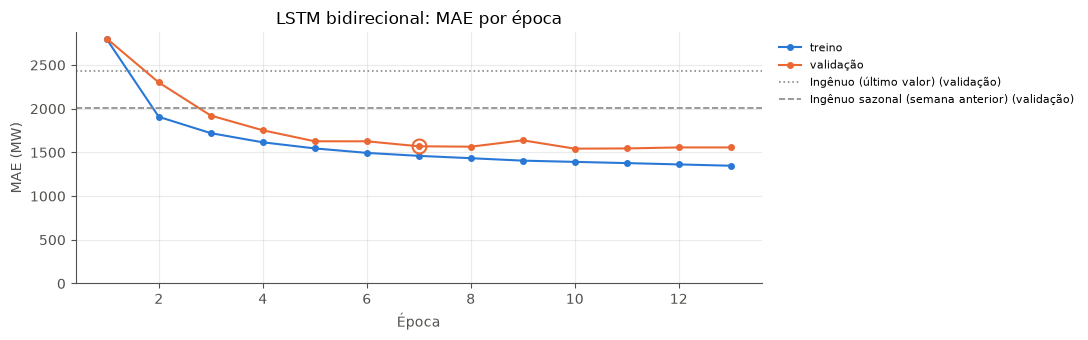

In [18]:
def lstm_bidirecional(inputs):
    x = layers.Bidirectional(layers.LSTM(16))(inputs)
    x = layers.Dropout(0.5)(x)
    return layers.Dense(1)(x)


modelo_bilstm = treinar('LSTM bidirecional', lstm_bidirecional)

## 7. Diagnóstico: por que o erro das redes cresce tanto no teste?

Na validação, a densa e as LSTMs erram bem menos que o ingênuo sazonal, mas no teste quase toda essa vantagem desaparece. Os gráficos abaixo mostram a causa: a carga média anual do SE/CO e o **viés** (erro médio, previsto − real) de cada método.

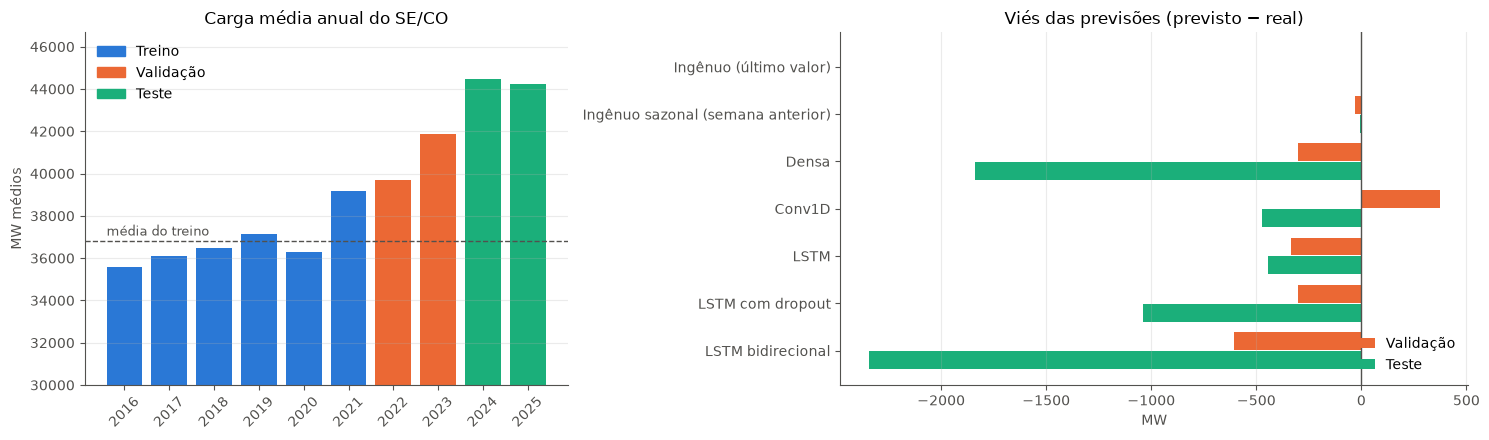

Carga máxima do SE/CO no treino: 52,889 MW (2.8 desvios padrão)
Horas do teste acima do máximo do treino: 8.1%
Carga máxima do SE/CO no teste: 62,150 MW (4.5 desvios padrão)


In [19]:
PERIODO_CORES = {'Treino': AZUL, 'Validação': LARANJA, 'Teste': VERDE}
anual = carga['SE'].groupby(carga.index.year).mean()
periodo = ['Treino' if a <= 2021 else 'Validação' if a <= 2023 else 'Teste' for a in anual.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})
ax1.bar(anual.index, anual.values, color=[PERIODO_CORES[p] for p in periodo], width=0.8)
ax1.axhline(mean[ALVO], color=TINTA_SECUNDARIA, ls='--', lw=1)
ax1.annotate('média do treino', (2015.6, mean[ALVO]), xytext=(0, 4), textcoords='offset points',
             fontsize=9, color=TINTA_SECUNDARIA)
ax1.set(title='Carga média anual do SE/CO', ylabel='MW médios', ylim=(30000, None), xticks=anual.index)
ax1.tick_params(axis='x', rotation=45)
ax1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in PERIODO_CORES.values()],
           labels=list(PERIODO_CORES), frameon=False, loc='upper left')
ax1.grid(axis='x', visible=False)

vies = pd.DataFrame({'Validação': {n: r['Viés (MW) val'] for n, r in resultados.items()},
                     'Teste': {n: r['Viés (MW) teste'] for n, r in resultados.items()}})
y = np.arange(len(vies))
for deslocamento, conjunto in [(-0.2, 'Validação'), (0.2, 'Teste')]:
    ax2.barh(y + deslocamento, vies[conjunto], height=0.38, color=PERIODO_CORES[conjunto], label=conjunto)
ax2.axvline(0, color=TINTA_SECUNDARIA, lw=1)
ax2.set(yticks=y, yticklabels=vies.index, title='Viés das previsões (previsto − real)', xlabel='MW')
ax2.invert_yaxis()
ax2.legend(frameon=False, loc='lower right')
ax2.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

maximo_treino = carga.loc[:'2021', 'SE'].max()
print(f'Carga máxima do SE/CO no treino: {maximo_treino:,.0f} MW ({(maximo_treino - mean[ALVO]) / std[ALVO]:.1f} desvios padrão)')
print(f'Horas do teste acima do máximo do treino: {(carga.loc["2024":, "SE"] > maximo_treino).mean():.1%}')
print(f'Carga máxima do SE/CO no teste: {carga.loc["2024":, "SE"].max():,.0f} MW '
      f'({(carga.loc["2024":, "SE"].max() - mean[ALVO]) / std[ALVO]:.1f} desvios padrão)')

A série tem **tendência de crescimento**: a carga média do SE/CO no teste (2024–2025) está cerca de 7.500 MW acima da média do treino, e parte das horas do teste fica acima do maior valor visto no treino. Na escala normalizada, a rede recebe entradas fora da faixa em que foi treinada e **não extrapola**: as unidades `tanh` e `sigmoid` das LSTMs saturam, e a densa aprendeu uma relação que só vale no intervalo do treino. O resultado é um **viés negativo** (subestimação sistemática) que cresce de 2022 para 2025.

Os ingênuos não têm esse problema: copiar o passado funciona em qualquer nível de carga, por isso o viés deles fica perto de zero. É essa ideia que uso para corrigir as redes.

## 8. Correção: normalização por janela

A divisão temporal e a geração do dataset (seção 4) continuam **exatamente as mesmas**. A mudança é uma camada no início do modelo:

1. Para cada janela, calculo o **nível** de cada série de carga: a média dos 168 valores da própria janela.
2. Subtraio esse nível das quatro colunas de carga. A rede passa a ver só a **forma** da última semana (quanto cada hora está acima ou abaixo da média da semana), que tem a mesma faixa de valores em 2016 e em 2025. As colunas de calendário não mudam.
3. A rede prevê o **desvio** do alvo em relação ao nível do SE/CO, e a camada `Add` soma o nível de volta na saída.

O nível é calculado só com os dados de entrada da própria janela, então não há vazamento de informação do futuro. É a mesma ideia da *reversible instance normalization* (RevIN, Kim et al., ICLR 2022), usada em modelos recentes de previsão justamente para lidar com mudanças de nível entre treino e teste.

Retreino as mesmas cinco arquiteturas, com a mesma configuração, só acrescentando essa camada.

In [20]:
from keras import ops

N_CARGAS = len(SUBSISTEMAS)


@keras.saving.register_keras_serializable(package='tarefa3')
class NormalizacaoPorJanela(layers.Layer):
    # Devolve a janela com as cargas centradas na própria média e o nível (média na janela) do alvo.
    def call(self, x):
        nivel = ops.mean(x[..., :N_CARGAS], axis=1, keepdims=True)
        relativo = ops.concatenate([x[..., :N_CARGAS] - nivel, x[..., N_CARGAS:]], axis=-1)
        return relativo, nivel[:, 0, ALVO:ALVO + 1]


def com_normalizacao_por_janela(construir):
    def construir_normalizado(inputs):
        relativo, nivel = NormalizacaoPorJanela()(inputs)
        return layers.Add()([construir(relativo), nivel])
    return construir_normalizado


amostras, _ = next(iter(test_dataset))
relativo, nivel = NormalizacaoPorJanela()(amostras)
print(f'Teste, cargas na escala global:   média {ops.mean(amostras[..., :N_CARGAS]):+.2f} | máx {ops.max(amostras[..., :N_CARGAS]):.2f}')
print(f'Teste, cargas relativas ao nível: média {ops.mean(relativo[..., :N_CARGAS]):+.2f} | máx {ops.max(relativo[..., :N_CARGAS]):.2f}')

Teste, cargas na escala global:   média +2.18 | máx 5.11
Teste, cargas relativas ao nível: média +0.00 | máx 2.64


Densa_norm_janela: 21,537 parâmetros
Epoch 1/30


205/205 - 4s - 21ms/step - loss: 0.1726 - mae: 0.2900 - val_loss: 0.1210 - val_mae: 0.2584


Epoch 2/30


205/205 - 4s - 19ms/step - loss: 0.0896 - mae: 0.2136 - val_loss: 0.1190 - val_mae: 0.2573


Epoch 3/30


...

205/205 - 3s - 16ms/step - loss: 0.0514 - mae: 0.1557 - val_loss: 0.0774 - val_mae: 0.1974


Epoch 19/30


205/205 - 3s - 16ms/step - loss: 0.0510 - mae: 0.1547 - val_loss: 0.0828 - val_mae: 0.2067


Tempo de treino: 68 s


Densa + norm. janela: Validation MAE: 1115 MW (2.75%) | Test MAE: 1308 MW (2.96%)


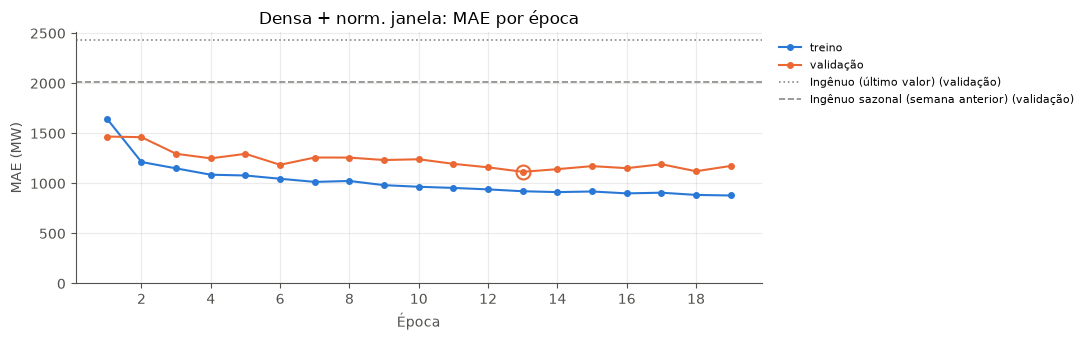

In [21]:
modelo_densa_nj = treinar('Densa + norm. janela', com_normalizacao_por_janela(densa))

Conv1D_norm_janela: 2,721 parâmetros
Epoch 1/30


205/205 - 6s - 28ms/step - loss: 0.4998 - mae: 0.5810 - val_loss: 0.2741 - val_mae: 0.4115


Epoch 2/30


205/205 - 5s - 23ms/step - loss: 0.1909 - mae: 0.3372 - val_loss: 0.1999 - val_mae: 0.3417


Epoch 3/30


...

205/205 - 9s - 45ms/step - loss: 0.1261 - mae: 0.2628 - val_loss: 0.1656 - val_mae: 0.3034


Epoch 16/30


205/205 - 5s - 26ms/step - loss: 0.1228 - mae: 0.2586 - val_loss: 0.1649 - val_mae: 0.3081


Tempo de treino: 86 s


Conv1D + norm. janela: Validation MAE: 1718 MW (4.24%) | Test MAE: 1852 MW (4.15%)


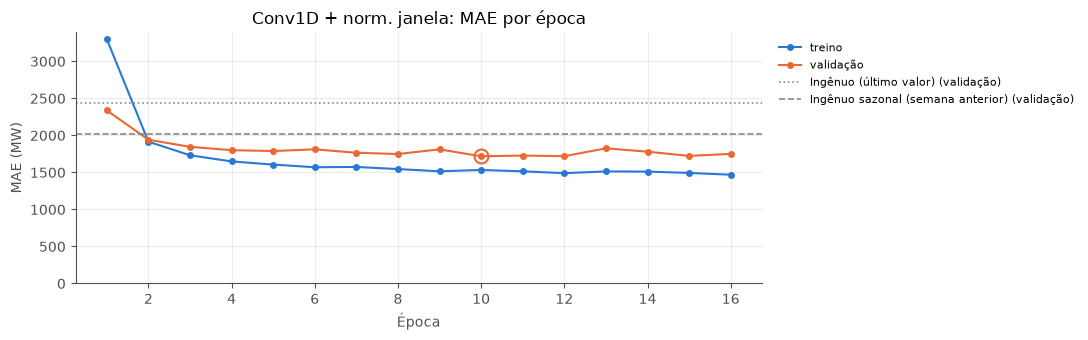

In [22]:
modelo_conv_nj = treinar('Conv1D + norm. janela', com_normalizacao_por_janela(convolucional))

LSTM_norm_janela: 1,617 parâmetros
Epoch 1/30


205/205 - 17s - 85ms/step - loss: 0.4224 - mae: 0.4916 - val_loss: 0.1563 - val_mae: 0.2953


Epoch 2/30


205/205 - 14s - 68ms/step - loss: 0.1034 - mae: 0.2317 - val_loss: 0.1060 - val_mae: 0.2326


Epoch 3/30


...

205/205 - 22s - 109ms/step - loss: 0.0495 - mae: 0.1467 - val_loss: 0.0735 - val_mae: 0.1822


Epoch 19/30


205/205 - 20s - 95ms/step - loss: 0.0489 - mae: 0.1459 - val_loss: 0.0745 - val_mae: 0.1836


Tempo de treino: 302 s


LSTM + norm. janela: Validation MAE: 1035 MW (2.57%) | Test MAE: 1178 MW (2.68%)


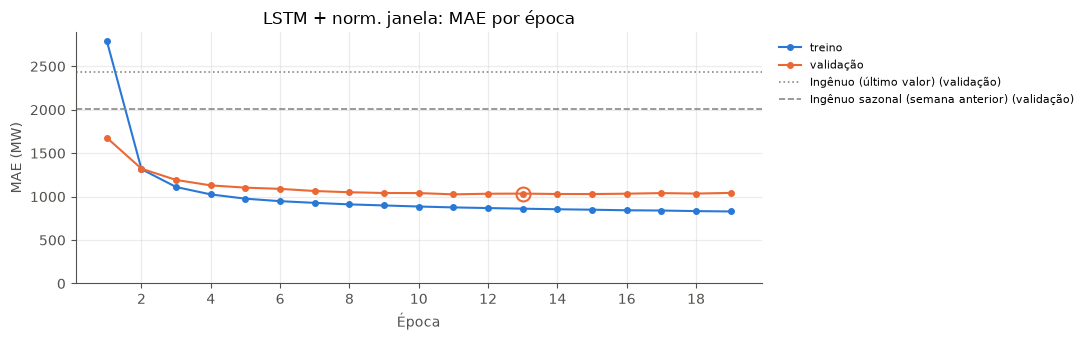

In [23]:
modelo_lstm_nj = treinar('LSTM + norm. janela', com_normalizacao_por_janela(lstm))

LSTM_com_dropout_norm_janela: 1,617 parâmetros
Epoch 1/30


205/205 - 20s - 97ms/step - loss: 0.3980 - mae: 0.4944 - val_loss: 0.1583 - val_mae: 0.3034


Epoch 2/30


205/205 - 18s - 86ms/step - loss: 0.2001 - mae: 0.3446 - val_loss: 0.1286 - val_mae: 0.2660


Epoch 3/30


...

205/205 - 22s - 107ms/step - loss: 0.1096 - mae: 0.2437 - val_loss: 0.0776 - val_mae: 0.1924


Epoch 29/30


205/205 - 19s - 94ms/step - loss: 0.1089 - mae: 0.2433 - val_loss: 0.0783 - val_mae: 0.1935


Tempo de treino: 529 s


LSTM com dropout + norm. janela: Validation MAE: 1075 MW (2.68%) | Test MAE: 1173 MW (2.66%)


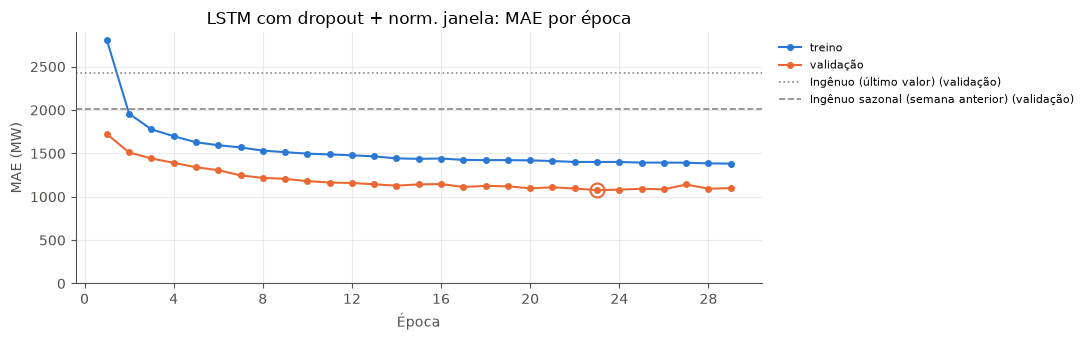

In [24]:
modelo_lstm_dropout_nj = treinar('LSTM com dropout + norm. janela', com_normalizacao_por_janela(lstm_dropout))

LSTM_bidirecional_norm_janela: 3,233 parâmetros
Epoch 1/30


205/205 - 27s - 130ms/step - loss: 0.3255 - mae: 0.4383 - val_loss: 0.1401 - val_mae: 0.2810


Epoch 2/30


205/205 - 22s - 109ms/step - loss: 0.1628 - mae: 0.3073 - val_loss: 0.1133 - val_mae: 0.2483


Epoch 3/30


...

205/205 - 21s - 103ms/step - loss: 0.0884 - mae: 0.2176 - val_loss: 0.0852 - val_mae: 0.2011


Epoch 20/30


205/205 - 20s - 99ms/step - loss: 0.0874 - mae: 0.2163 - val_loss: 0.0824 - val_mae: 0.1976


Tempo de treino: 431 s


LSTM bidirecional + norm. janela: Validation MAE: 1125 MW (2.82%) | Test MAE: 1165 MW (2.65%)


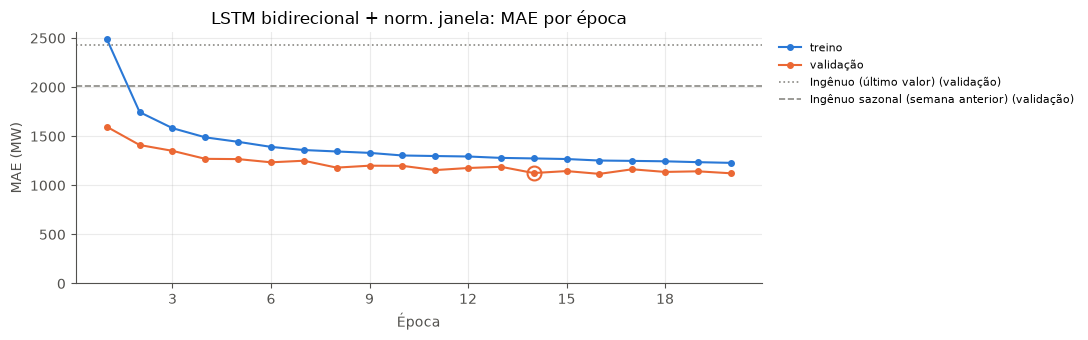

In [25]:
modelo_bilstm_nj = treinar('LSTM bidirecional + norm. janela', com_normalizacao_por_janela(lstm_bidirecional))

## 9. Comparação no conjunto de teste (2024–2025)

O conjunto de teste só é usado aqui, depois de todas as escolhas feitas. A tabela traz os erros na validação e no teste, o viés e o ganho em relação ao ingênuo sazonal.

In [26]:
tabela = pd.DataFrame(resultados).T
baseline_mae = tabela.loc['Ingênuo sazonal (semana anterior)', 'MAE (MW) teste']
tabela['Ganho sobre o ingênuo sazonal (teste)'] = 1 - tabela['MAE (MW) teste'] / baseline_mae
tabela.style.format({'MAE (MW) val': '{:,.0f}', 'MAE (MW) teste': '{:,.0f}', 'MAPE (%) val': '{:.2f}',
                     'MAPE (%) teste': '{:.2f}', 'Viés (MW) val': '{:+,.0f}', 'Viés (MW) teste': '{:+,.0f}',
                     'Ganho sobre o ingênuo sazonal (teste)': '{:+.1%}'})

,MAE (MW) val,MAPE (%) val,Viés (MW) val,MAE (MW) teste,MAPE (%) teste,Viés (MW) teste,Ganho sobre o ingênuo sazonal (teste)
Ingênuo (último valor),"2,431",6.11,-1,"2,585",5.92,+3,-11.8%
Ingênuo sazonal (semana anterior),"2,013",4.96,-28,"2,312",5.24,-4,+0.0%
Densa,"1,301",3.19,-302,"2,232",5.14,"-1,839",+3.4%
Conv1D,"2,026",5.04,+373,"2,521",5.67,-472,-9.1%
LSTM,"1,276",3.09,-334,"2,154",4.82,-446,+6.8%
LSTM com dropout,"1,362",3.33,-300,"2,112",4.67,"-1,041",+8.6%
LSTM bidirecional,"1,570",3.72,-606,"3,080",6.56,"-2,344",-33.2%
Densa + norm. janela,"1,115",2.75,-180,"1,308",2.96,-613,+43.4%
Conv1D + norm. janela,"1,718",4.24,-16,"1,852",4.15,-592,+19.9%
LSTM + norm. janela,"1,035",2.57,-18,"1,178",2.68,-261,+49.0%


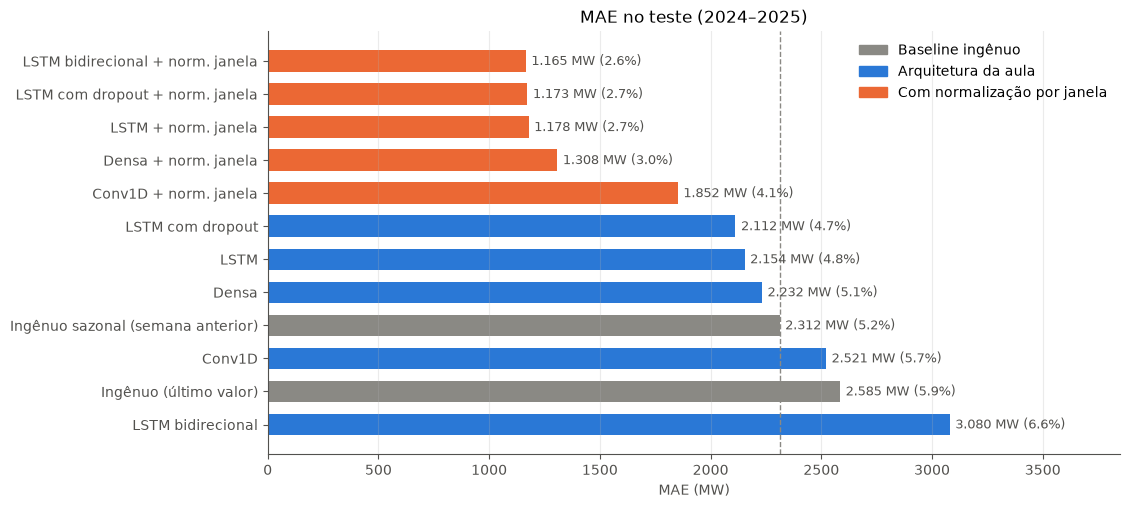

In [27]:
GRUPOS = {'Baseline ingênuo': CINZA, 'Arquitetura da aula': AZUL, 'Com normalização por janela': LARANJA}


def grupo(nome):
    if nome.startswith('Ingênuo'):
        return 'Baseline ingênuo'
    return 'Com normalização por janela' if nome.endswith('norm. janela') else 'Arquitetura da aula'


ordem = tabela['MAE (MW) teste'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.5))
barras = ax.barh(ordem.index, ordem.values, color=[GRUPOS[grupo(n)] for n in ordem.index], height=0.65)
ax.bar_label(barras, labels=[f'{v:,.0f} MW ({tabela.loc[n, "MAPE (%) teste"]:.1f}%)'.replace(',', '.')
                             for n, v in ordem.items()], padding=4, fontsize=9, color=TINTA_SECUNDARIA)
ax.axvline(baseline_mae, color=CINZA, ls='--', lw=1)
ax.set(title='MAE no teste (2024–2025)', xlabel='MAE (MW)', xlim=(0, ordem.max() * 1.25))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GRUPOS.values()], labels=list(GRUPOS),
          frameon=False, loc='upper right')
ax.grid(axis='y', visible=False)
plt.show()

Para ver como os erros aparecem na prática, desenho a carga real e as previsões do ingênuo sazonal e da melhor rede de cada grupo (escolhida pela **validação**) em dois trechos do teste: duas semanas comuns e a semana do **Carnaval de 2025** (3 e 4 de março), um feriado móvel que nenhum dos métodos conhece explicitamente.

Melhor de cada grupo na validação: {'Baseline ingênuo': 'Ingênuo sazonal (semana anterior)', 'Arquitetura da aula': 'LSTM', 'Com normalização por janela': 'LSTM + norm. janela'}


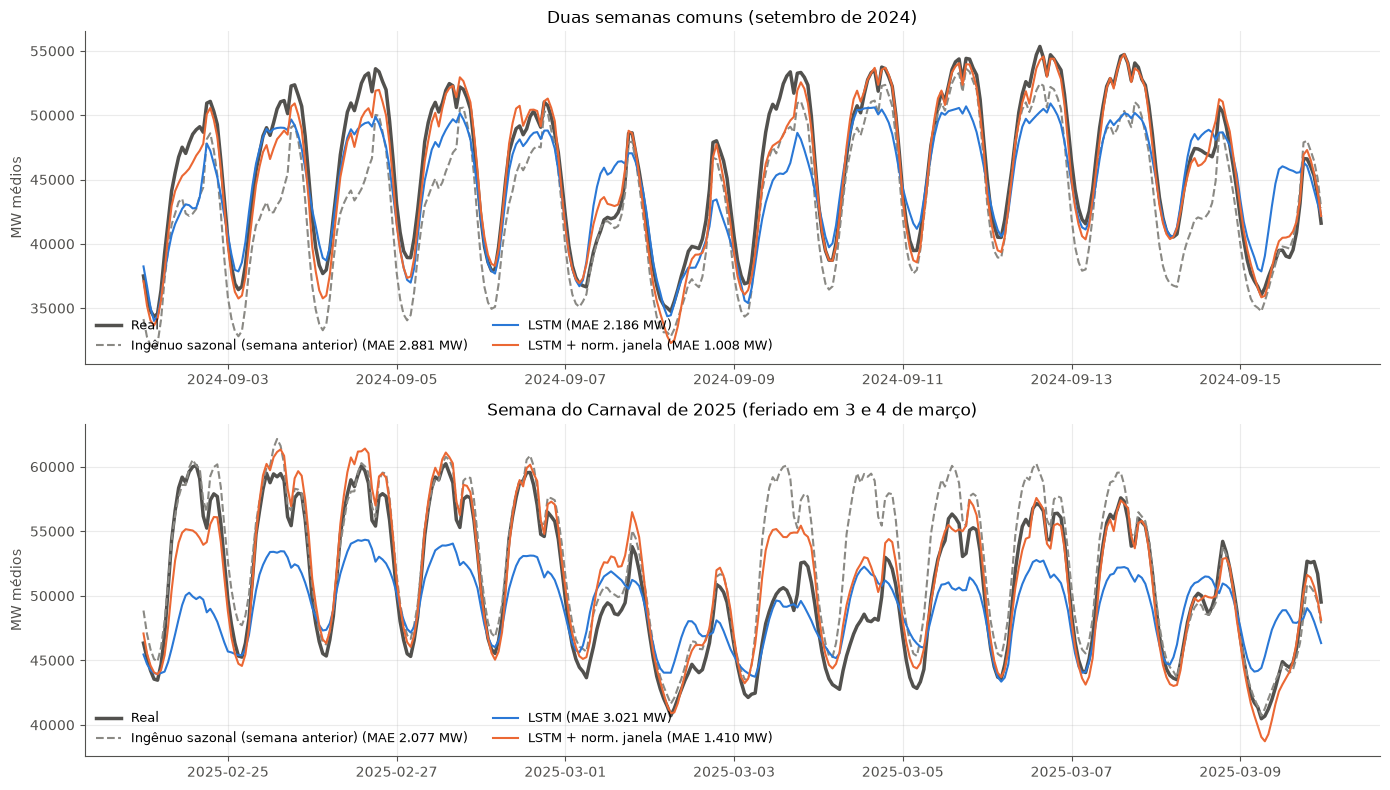

In [28]:
real_teste = reais['teste']
instantes_teste = carga.index[fim_val + delay: fim_val + delay + len(real_teste)]
assert np.allclose(real_teste, carga.loc[instantes_teste, 'SE'].to_numpy(), rtol=1e-4)

melhor = {g: tabela.loc[[n for n in tabela.index if grupo(n) == g], 'MAE (MW) val'].idxmin() for g in GRUPOS}
print('Melhor de cada grupo na validação:', melhor)

curvas = {'Real': real_teste} | {melhor[g]: previsoes[melhor[g], 'teste'] for g in GRUPOS}
curvas = pd.DataFrame(curvas, index=instantes_teste)
estilos = {melhor['Baseline ingênuo']: dict(color=CINZA, ls='--'),
           melhor['Arquitetura da aula']: dict(color=AZUL),
           melhor['Com normalização por janela']: dict(color=LARANJA)}

fig, eixos = plt.subplots(2, 1, figsize=(14, 8))
for ax, (inicio, fim, titulo) in zip(eixos, [('2024-09-02', '2024-09-15 23:00', 'Duas semanas comuns (setembro de 2024)'),
                                              ('2025-02-24', '2025-03-09 23:00', 'Semana do Carnaval de 2025 (feriado em 3 e 4 de março)')]):
    trecho = curvas.loc[inicio:fim]
    ax.plot(trecho.index, trecho['Real'], color=TINTA_SECUNDARIA, lw=2.5, label='Real')
    for nome, estilo in estilos.items():
        mae = np.mean(np.abs(trecho[nome] - trecho['Real']))
        ax.plot(trecho.index, trecho[nome], **estilo, label=f'{nome} (MAE {mae:,.0f} MW)'.replace(',', '.'))
    ax.set(title=titulo, ylabel='MW médios')
    ax.legend(frameon=False, ncol=2, loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

Por fim, o MAE no teste por dia da semana do alvo mostra onde cada método erra mais:

In [29]:
erros_abs = pd.DataFrame({nome: np.abs(previsoes[nome, 'teste'] - real_teste) for nome in resultados}, index=instantes_teste)
erro_dia = erros_abs.groupby(erros_abs.index.dayofweek).mean().T
erro_dia.columns = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
erro_dia.round(0).astype(int)

,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
Ingênuo (último valor),6168,1460,1203,1182,1122,3646,3336
Ingênuo sazonal (semana anterior),2374,2393,2437,2615,2613,1989,1759
Densa,3045,2082,1610,2185,2476,2046,2188
Conv1D,2702,2239,2622,2572,2827,2453,2236
LSTM,3217,1910,1913,2010,1929,1854,2246
LSTM com dropout,3248,1553,1982,2246,2109,1467,2187
LSTM bidirecional,5903,2529,2647,3357,3806,1647,1678
Densa + norm. janela,1639,1262,1262,1380,1283,1151,1177
Conv1D + norm. janela,1959,1752,1866,1970,2207,1704,1508
LSTM + norm. janela,1619,1074,1157,1160,1138,1114,987


## 10. Conclusões

**Base e parâmetros.** A curva de carga horária do ONS tem a mesma estrutura da base de Jena (várias séries medidas em intervalos regulares), mas com ciclos diário e semanal muito mais fortes. Isso orientou a geração do dataset: `sampling_rate = 1` porque os dados já são horários, `sequence_length = 168` porque o ciclo semanal é o mais forte (autocorrelação de 0,894 em 168 h, contra 0,810 em 24 h) e `delay = 191` para que o alvo fique 24 h depois da última medição, que é a previsão do dia seguinte.

**Baselines.** O ingênuo da aula (último valor) aqui equivale a "amanhã nesta hora será igual a hoje nesta hora". Ele erra 2.585 MW (5,9%) no teste e quase todo o erro está nas trocas entre dia útil e fim de semana: erra 6.168 MW nas segundas e mais de 3.300 MW nos sábados e domingos, contra cerca de 1.200 MW de terça a sexta. O ingênuo sazonal (semana anterior) corrige isso e é o baseline mais difícil: **2.312 MW (5,2%)**.

**Arquiteturas da aula.** Na validação, a densa e as LSTMs ficaram até 37% abaixo do ingênuo sazonal (LSTM: 1.276 contra 2.013 MW). No teste a vantagem praticamente sumiu: o melhor resultado foi o da LSTM com dropout, só 8,6% melhor (2.112 MW), e a Conv1D (2.521 MW) e a LSTM bidirecional (3.080 MW) ficaram **piores que o ingênuo**. A seção 7 mostrou a causa: a carga do SE/CO cresceu de 36.800 MW de média no treino para cerca de 44.300 MW em 2024–2025, 8,1% das horas do teste ficam acima do máximo do treino, e as redes, que não extrapolam, passam a subestimar sistematicamente (viés de até −2.344 MW). Essa é a lição da aula sobre baselines levada um passo adiante: além de comparar com um método ingênuo, é preciso fazer essa comparação em um período que represente o uso real, porque uma divisão treino/teste no tempo pode esconder uma mudança de distribuição.

**Normalização por janela.** Tirando o nível de cada janela antes da rede e somando-o de volta na saída (sem mudar nada na geração do dataset), as cinco arquiteturas melhoraram no teste. As três LSTMs chegaram a **1.165–1.178 MW (≈ 2,7%), cerca de 49% abaixo do ingênuo sazonal**, o viés caiu para menos de 300 MW, e a diferença entre validação e teste ficou pequena (LSTM: 1.035 → 1.178 MW, contra 1.276 → 2.154 MW antes). A correção também melhorou o erro de todos os dias da semana.

**Comparação entre arquiteturas.** Com a correção:
- as redes recorrentes foram as melhores, e a densa ficou perto (1.308 MW), porque, com a janela achatada, ela consegue dar peso às posições mais informativas (mesma hora de ontem e da semana passada);
- a Conv1D foi a pior rede (1.852 MW). O `GlobalAveragePooling1D` faz a média das ativações ao longo de toda a janela e perde **onde** cada padrão aconteceu, e para prever a carga daqui a 24 h a posição importa muito (as últimas horas valem mais que as de seis dias atrás). Na aula ela também ficou atrás do ingênuo;
- a LSTM bidirecional não trouxe ganho relevante (1.165 contra 1.178 MW) com o dobro de parâmetros e de tempo, e o *dropout* teve efeito pequeno. Isso é coerente com a aula: em séries em que o passado recente é o mais informativo, ler a janela de trás para frente acrescenta pouco.

**Limitações e próximos passos.** Nenhum modelo conhece os feriados. Na semana do Carnaval de 2025 o erro da melhor rede subiu de cerca de 1.000 MW (semanas comuns) para 1.410 MW, e o ingênuo sazonal errou ainda mais por copiar uma semana sem feriado. As segundas-feiras continuam sendo o dia mais difícil. Variáveis indicadoras de feriado e a previsão de temperatura (a carga do SE/CO depende muito do uso de ar-condicionado) seriam as próximas entradas naturais, assim como prever as 24 horas do dia seguinte de uma vez, que é o formato usado na programação da operação.